In [35]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import joblib

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay
)

In [36]:
df = pd.read_csv('marketing_data.csv')
df.head()

,CustomerID,Age,Gender,Income,CampaignChannel,CampaignType,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,AdvertisingPlatform,AdvertisingTool,Conversion
0,8000,56,Female,136912,Social Media,Awareness,6497.870068,0.043919,0.088031,0,2.399017,7.396803,19,6,9,4,688,IsConfid,ToolConfid,1
1,8001,69,Male,41760,Email,Retention,3898.668606,0.155725,0.182725,42,2.917138,5.352549,5,2,7,2,3459,IsConfid,ToolConfid,1
2,8002,46,Female,88456,PPC,Awareness,1546.429596,0.277490,0.076423,2,8.223619,13.794901,0,11,2,8,2337,IsConfid,ToolConfid,1
3,8003,32,Female,44085,PPC,Conversion,539.525936,0.137611,0.088004,47,4.540939,14.688363,89,2,2,0,2463,IsConfid,ToolConfid,1
4,8004,60,Female,83964,PPC,Conversion,1678.043573,0.252851,0.109940,0,2.046847,13.993370,6,6,6,8,4345,IsConfid,ToolConfid,1


In [37]:
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (8000, 20)
Number of rows: 8000
Number of columns: 20


In [38]:
print("Column names:")

for column in df.columns:
    print(column)

Column names:
CustomerID
Age
Gender
Income
CampaignChannel
CampaignType
AdSpend
ClickThroughRate
ConversionRate
WebsiteVisits
PagesPerVisit
TimeOnSite
SocialShares
EmailOpens
EmailClicks
PreviousPurchases
LoyaltyPoints
AdvertisingPlatform
AdvertisingTool
Conversion


In [39]:
print(" ---Summary Statistics ---")
display(df.describe())

 ---Summary Statistics ---


,CustomerID,Age,Income,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,Conversion
count,8000.00000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,11999.50000,43.625500,84664.196750,5000.944830,0.154829,0.104389,24.751625,5.549299,7.727718,49.799750,9.476875,4.467375,4.485500,2490.268500,0.876500
std,2309.54541,14.902785,37580.387945,2838.038153,0.084007,0.054878,14.312269,2.607358,4.228218,28.901165,5.711111,2.856564,2.888093,1429.527162,0.329031
min,8000.00000,18.000000,20014.000000,100.054813,0.010005,0.010018,0.000000,1.000428,0.501669,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,9999.75000,31.000000,51744.500000,2523.221165,0.082635,0.056410,13.000000,3.302479,4.068340,25.000000,5.000000,2.000000,2.000000,1254.750000,1.000000
50%,11999.50000,43.000000,84926.500000,5013.440044,0.154505,0.104046,25.000000,5.534257,7.682956,50.000000,9.000000,4.000000,4.000000,2497.000000,1.000000
75%,13999.25000,56.000000,116815.750000,7407.989369,0.228207,0.152077,37.000000,7.835756,11.481468,75.000000,14.000000,7.000000,7.000000,3702.250000,1.000000
max,15999.00000,69.000000,149986.000000,9997.914781,0.299968,0.199995,49.000000,9.999055,14.995311,99.000000,19.000000,9.000000,9.000000,4999.000000,1.000000


In [40]:
df.describe(include="object")

C:\Users\Blessy\AppData\Local\Temp\ipykernel_43036\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Gender,CampaignChannel,CampaignType,AdvertisingPlatform,AdvertisingTool
count,8000,8000,8000,8000,8000
unique,2,5,4,1,1
top,Female,Referral,Conversion,IsConfid,ToolConfid
freq,4839,1719,2077,8000,8000


In [41]:
print("Missing values in each column:")

print(df.isnull().sum())

Missing values in each column:
CustomerID             0
Age                    0
Gender                 0
Income                 0
CampaignChannel        0
CampaignType           0
AdSpend                0
ClickThroughRate       0
ConversionRate         0
WebsiteVisits          0
PagesPerVisit          0
TimeOnSite             0
SocialShares           0
EmailOpens             0
EmailClicks            0
PreviousPurchases      0
LoyaltyPoints          0
AdvertisingPlatform    0
AdvertisingTool        0
Conversion             0
dtype: int64


In [42]:
X = df.drop(columns=['CustomerID', 'Conversion'])
y = df['Conversion']

In [43]:
print(df["Conversion"].value_counts())
print("\nConversion percentages:")
print(df["Conversion"].value_counts(normalize=True) * 100)

Conversion
1    7012
0     988
Name: count, dtype: int64

Conversion percentages:
Conversion
1    87.65
0    12.35
Name: proportion, dtype: float64


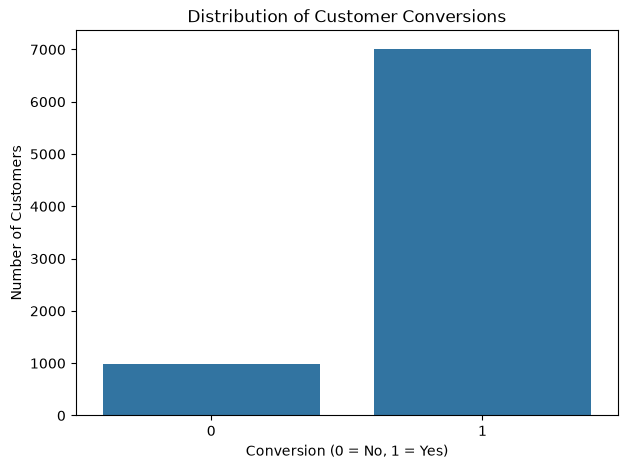

In [44]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Conversion")
plt.title("Distribution of Customer Conversions")
plt.xlabel("Conversion (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

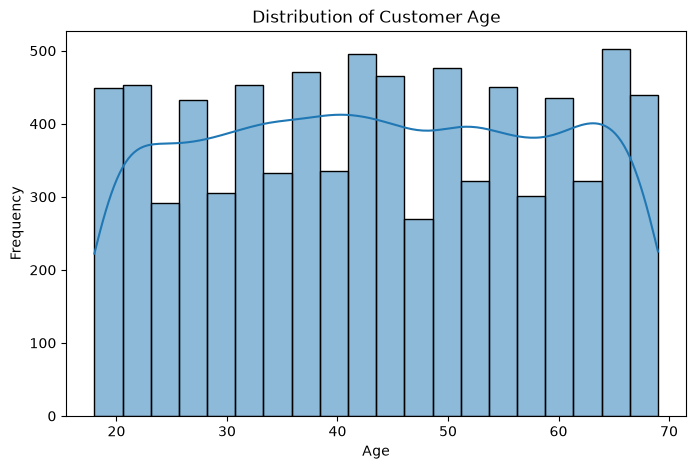

In [45]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Age", bins=20, kde=True)
plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

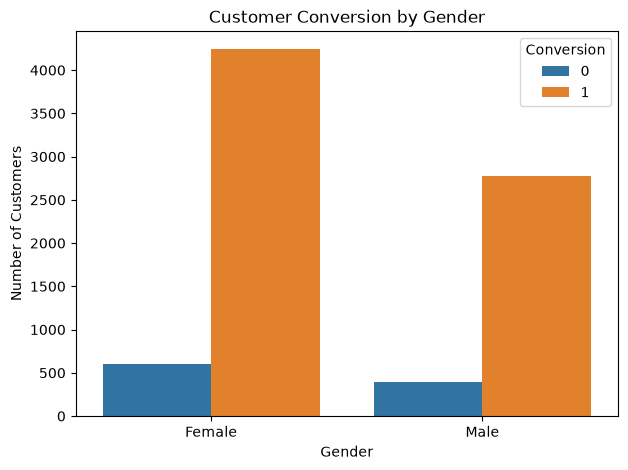

In [46]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Gender", hue="Conversion")
plt.title("Customer Conversion by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()

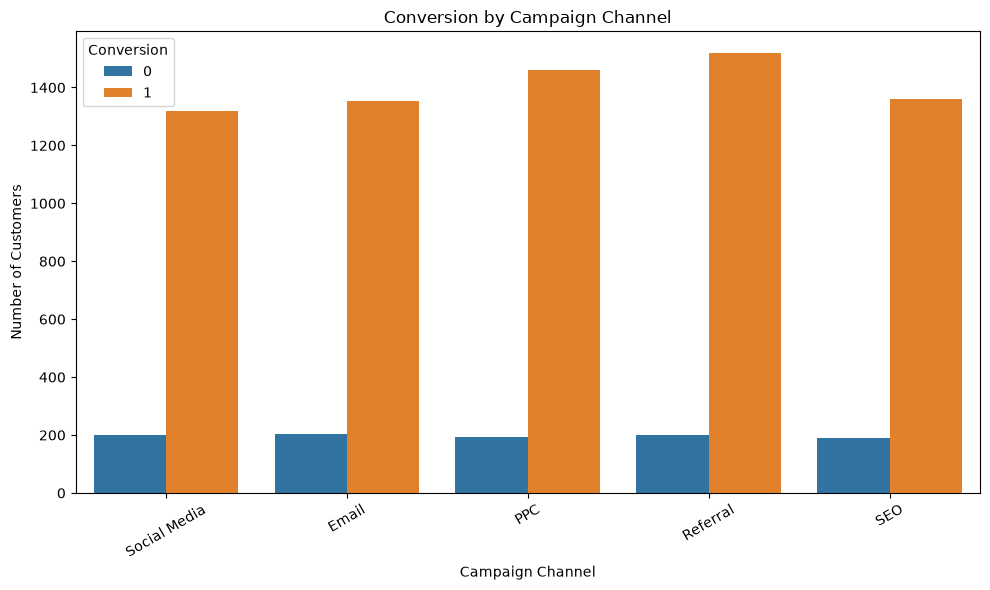

In [47]:
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df,
    x="CampaignChannel",
    hue="Conversion"
)
plt.title("Conversion by Campaign Channel")
plt.xlabel("Campaign Channel")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

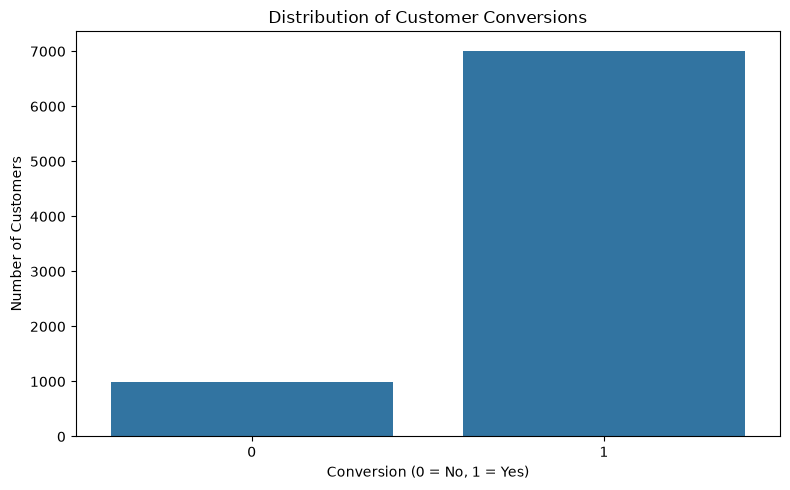

In [48]:

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Conversion")
plt.title("Distribution of Customer Conversions")
plt.xlabel("Conversion (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

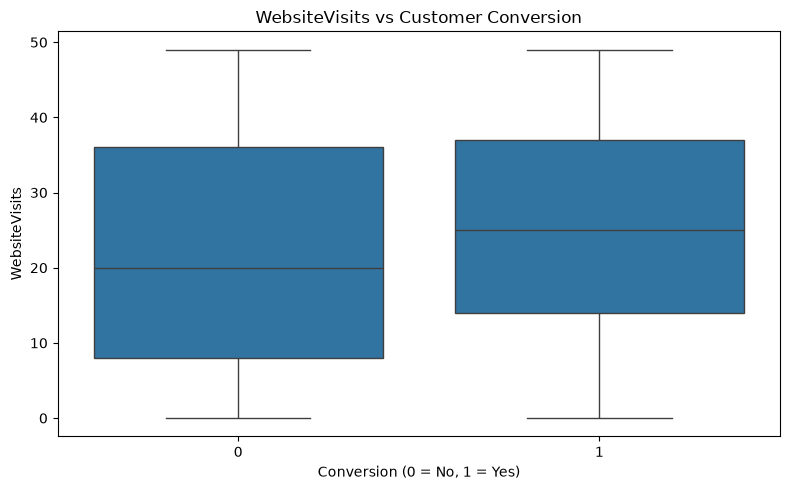

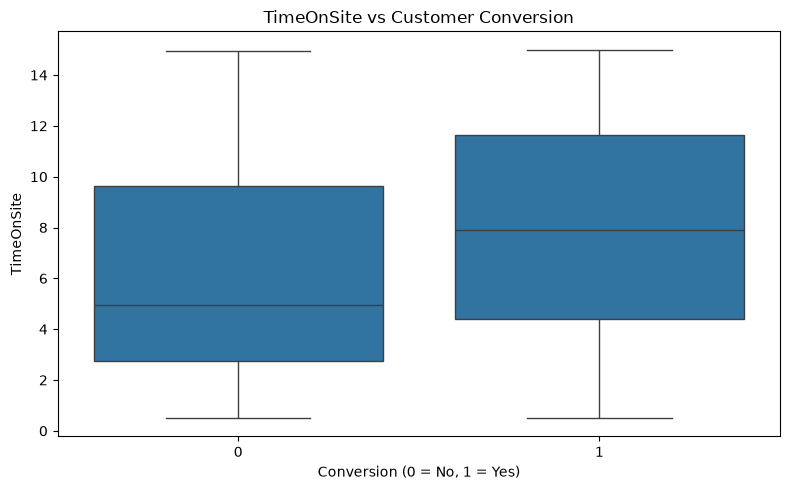

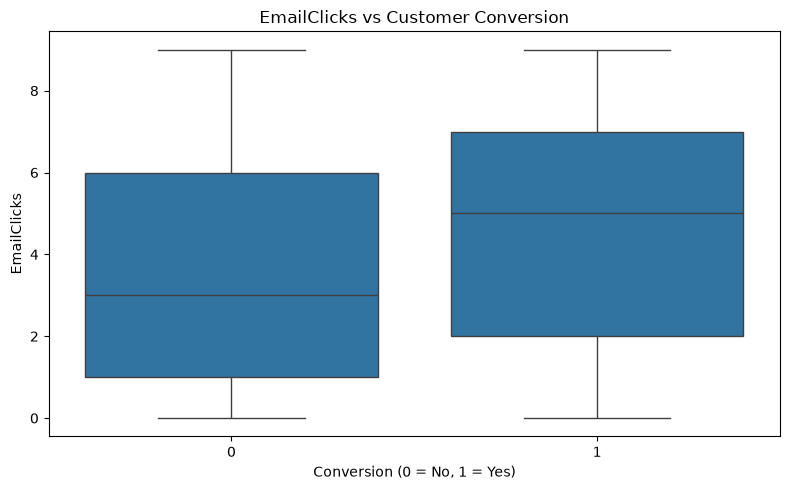

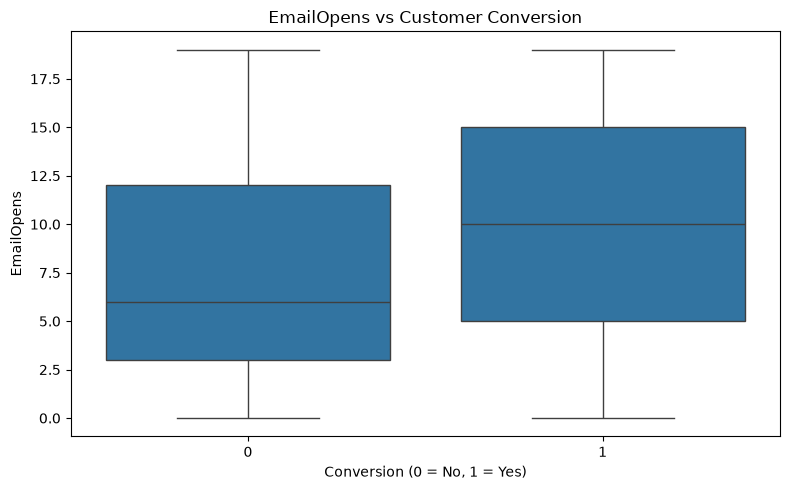

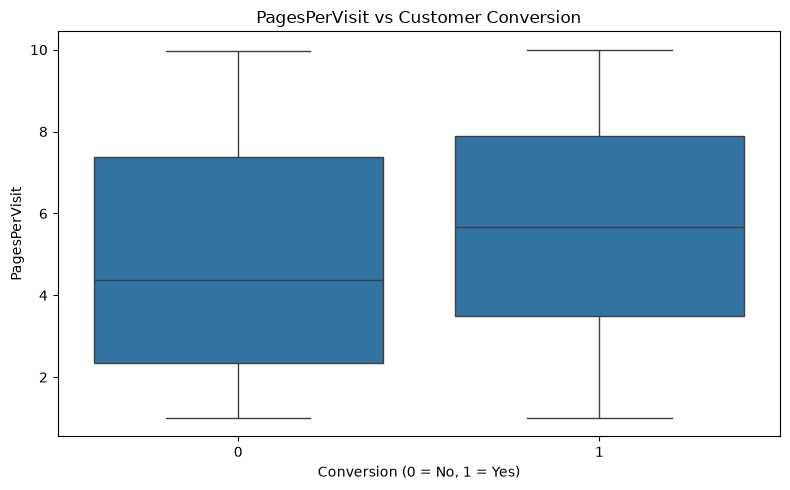

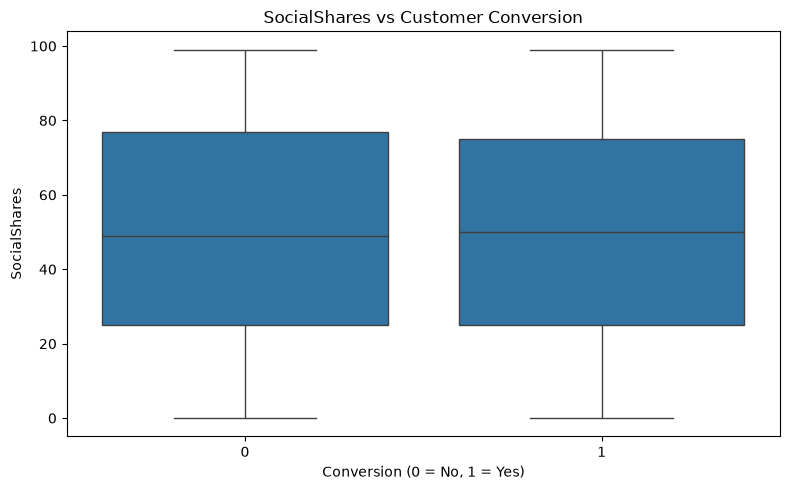

In [49]:
engagement_features = [
    "WebsiteVisits",
    "TimeOnSite",
    "EmailClicks",
    "EmailOpens",
    "PagesPerVisit",
    "SocialShares"
]
for feature in engagement_features:
    plt.figure(figsize=(8, 5))
    sns.boxplot(
        data=df,
        x="Conversion",
        y=feature
    )
    plt.title(f"{feature} vs Customer Conversion")
    plt.xlabel("Conversion (0 = No, 1 = Yes)")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

CampaignChannel
Referral        88.307155
PPC             88.277946
SEO             87.677419
Email           87.026333
Social Media    86.833443
Name: Conversion, dtype: float64


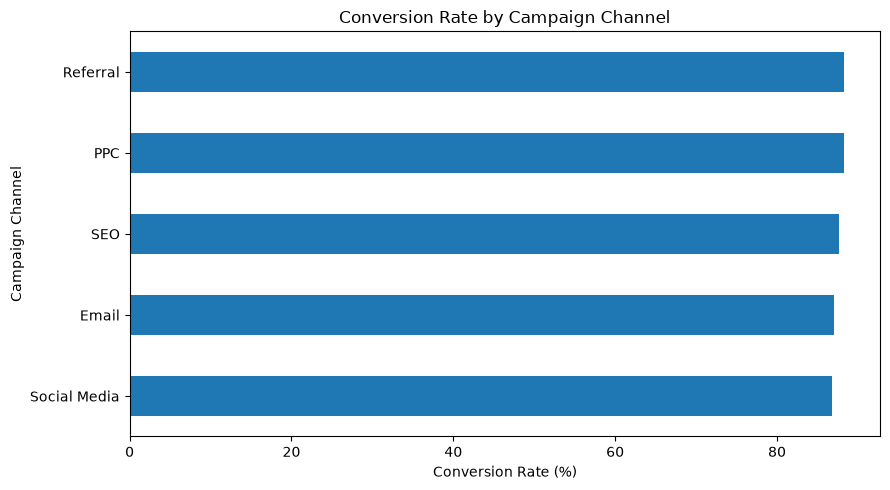

In [50]:
channel_conversion = df.groupby("CampaignChannel")["Conversion"].mean() * 100
print(channel_conversion.sort_values(ascending=False))
channel_conversion.sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)
plt.title("Conversion Rate by Campaign Channel")
plt.xlabel("Conversion Rate (%)")
plt.ylabel("Campaign Channel")
plt.tight_layout()
plt.show()

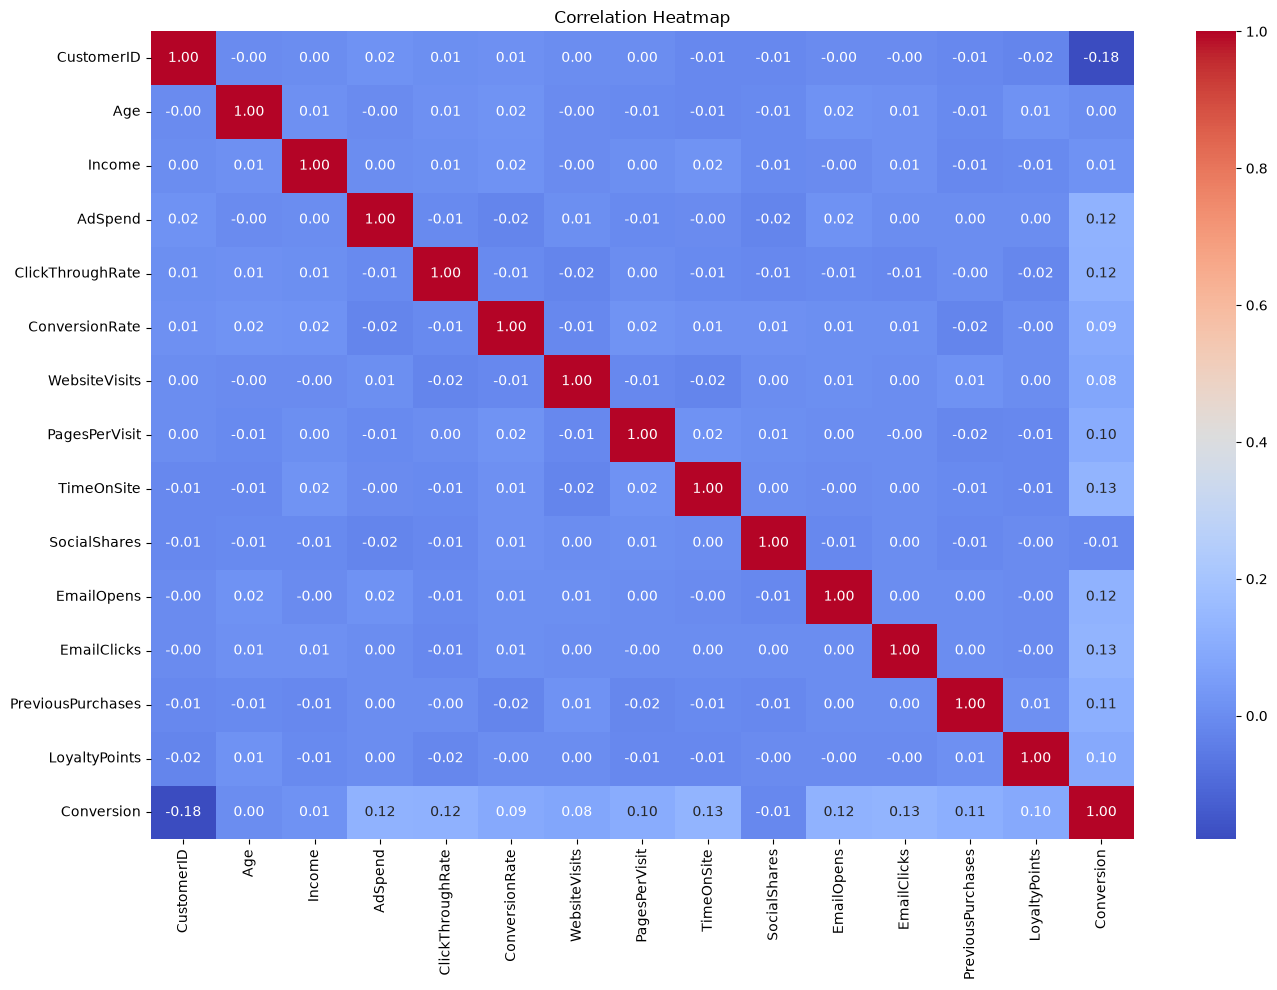

In [51]:
numeric_df = df.select_dtypes(include=np.number)
correlation_matrix = numeric_df.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [52]:
# Target variable
target = "Conversion"
# Remove the target and customer identifier from the features
X = df.drop(columns=["Conversion", "CustomerID"])
y = df[target]
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (8000, 18)
Target shape: (8000,)


In [53]:
# Use this if ConversionRate is unavailable at prediction time.
X = X.drop(columns=["ConversionRate"], errors="ignore")
print("Updated feature shape:", X.shape)

Updated feature shape: (8000, 17)


In [54]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)
print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Age', 'Income', 'AdSpend', 'ClickThroughRate', 'WebsiteVisits', 'PagesPerVisit', 'TimeOnSite', 'SocialShares', 'EmailOpens', 'EmailClicks', 'PreviousPurchases', 'LoyaltyPoints']

Categorical features:
['Gender', 'CampaignChannel', 'CampaignType', 'AdvertisingPlatform', 'AdvertisingTool']


C:\Users\Blessy\AppData\Local\Temp\ipykernel_43036\582130550.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [55]:
# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())])
# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [56]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 6400
Testing samples: 1600


In [57]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )}

In [58]:
trained_models = {}
results = []

for name, model in models.items():
    # Combine preprocessing and model
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )

    # Train the model
    pipeline.fit(X_train, y_train)

    # Predict test-set labels
    
    y_pred = pipeline.predict(X_test)
    # Predict conversion probabilities
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    
    # Calculate evaluation metrics
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )
    auc = roc_auc_score(y_test, y_prob)
    # Store the trained model
    
    trained_models[name] = pipeline
    
    # Store evaluation results
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc
    })

# Create comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

print(results_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
  Gradient Boosting    0.9119     0.9140  0.9929    0.9518   0.8057
      Random Forest    0.9088     0.9187  0.9829    0.9497   0.7913
      Decision Tree    0.8206     0.8991  0.8959    0.8975   0.5919
Logistic Regression    0.7319     0.9484  0.7340    0.8275   0.7698


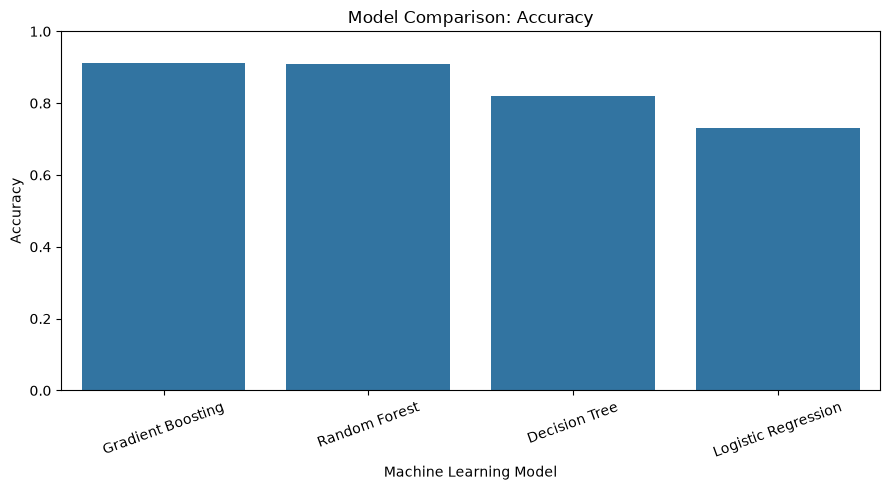

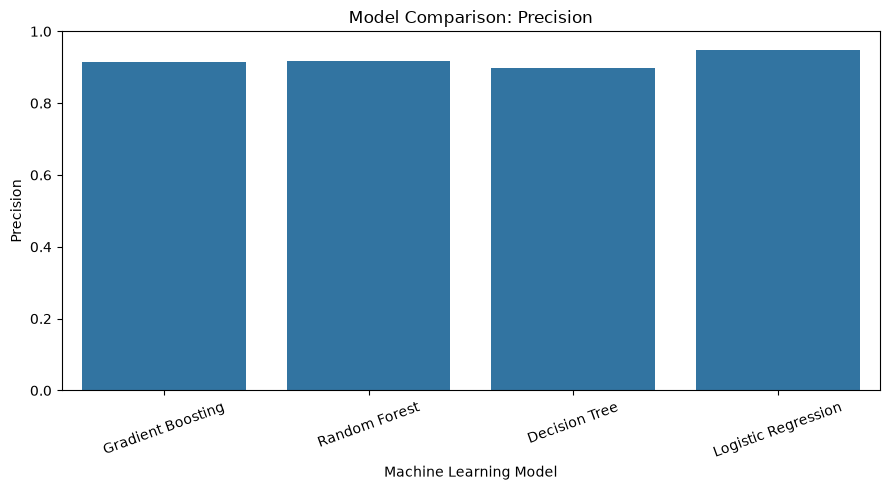

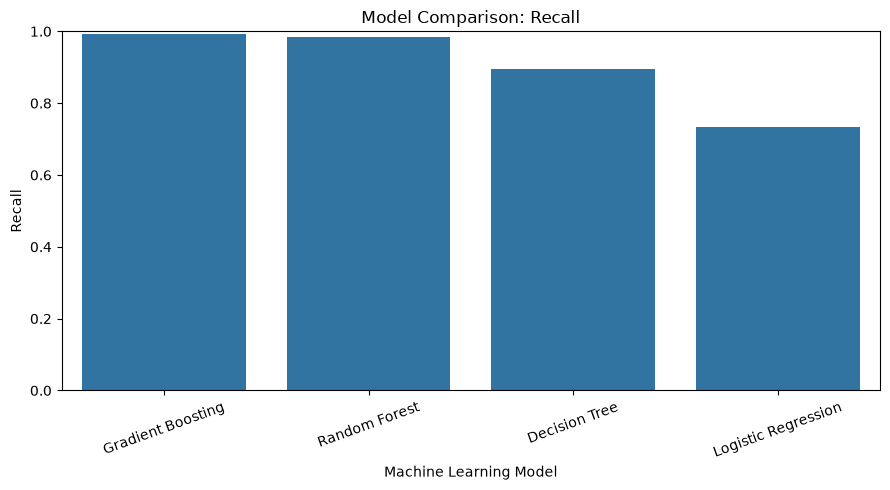

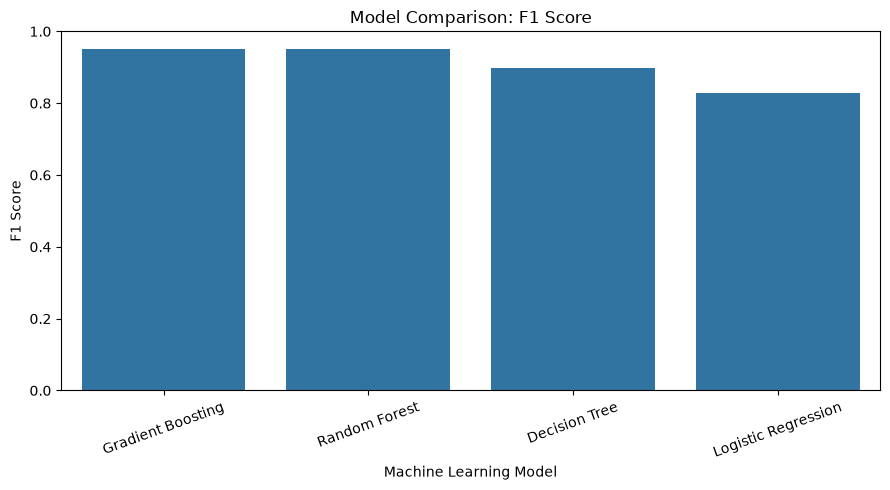

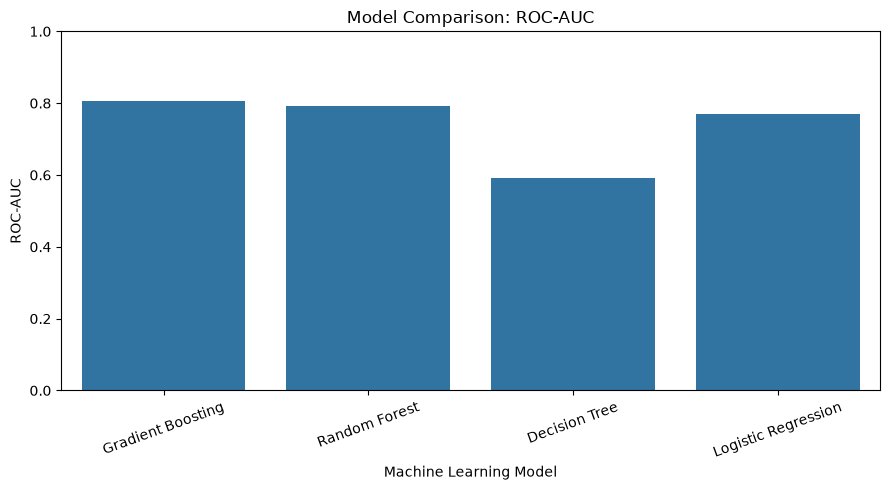

In [59]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

for metric in metrics:

    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )
    plt.title(f"Model Comparison: {metric}")
    plt.ylabel(metric)
    plt.xlabel("Machine Learning Model")
    plt.xticks(rotation=20)
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

In [60]:
best_model_name = results_df.iloc[0]["Model"]
best_model= trained_models[best_model_name]
print("Best model based on F1-score:", best_model_name)

Best model based on F1-score: Gradient Boosting


In [61]:
y_pred = best_model.predict(X_test)

print("Selected Model:", best_model_name)
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Not Converted",
            "Converted"
        ],
        zero_division=0
    )
)

Selected Model: Gradient Boosting

Classification Report:
               precision    recall  f1-score   support

Not Converted       0.87      0.34      0.49       198
    Converted       0.91      0.99      0.95      1402

     accuracy                           0.91      1600
    macro avg       0.89      0.67      0.72      1600
 weighted avg       0.91      0.91      0.89      1600



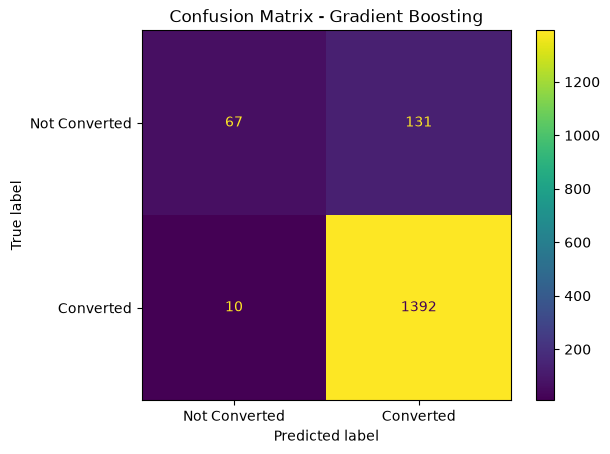

In [62]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Not Converted",
        "Converted"
    ]
)

disp.plot()
plt.title(f"Confusion Matrix - {best_model_name}")

plt.show()

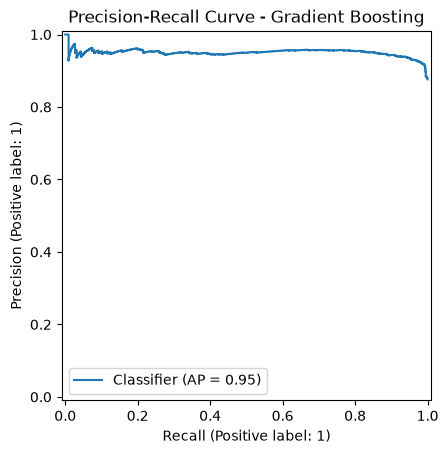

In [63]:
y_prob = best_model.predict_proba(X_test)[:, 1]

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title(f"Precision-Recall Curve - {best_model_name}")

plt.show()

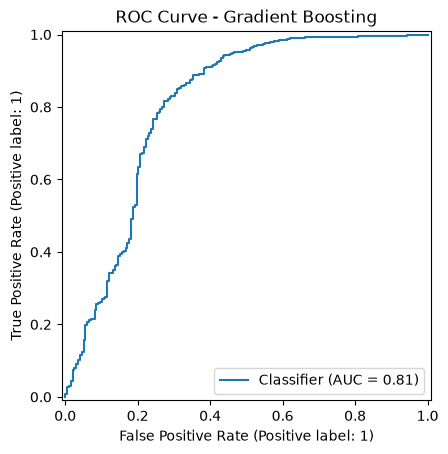

In [64]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title(f"ROC Curve - {best_model_name}")

plt.show()

                            Feature  Importance
2                      num__AdSpend    0.138823
6                   num__TimeOnSite    0.127349
5                num__PagesPerVisit    0.123536
3             num__ClickThroughRate    0.116854
10           num__PreviousPurchases    0.107893
11               num__LoyaltyPoints    0.093439
9                  num__EmailClicks    0.089322
8                   num__EmailOpens    0.068772
4                num__WebsiteVisits    0.059056
21     cat__CampaignType_Conversion    0.054135
1                       num__Income    0.008533
0                          num__Age    0.004174
7                 num__SocialShares    0.003875
20  cat__CampaignType_Consideration    0.002688
16    cat__CampaignChannel_Referral    0.000639


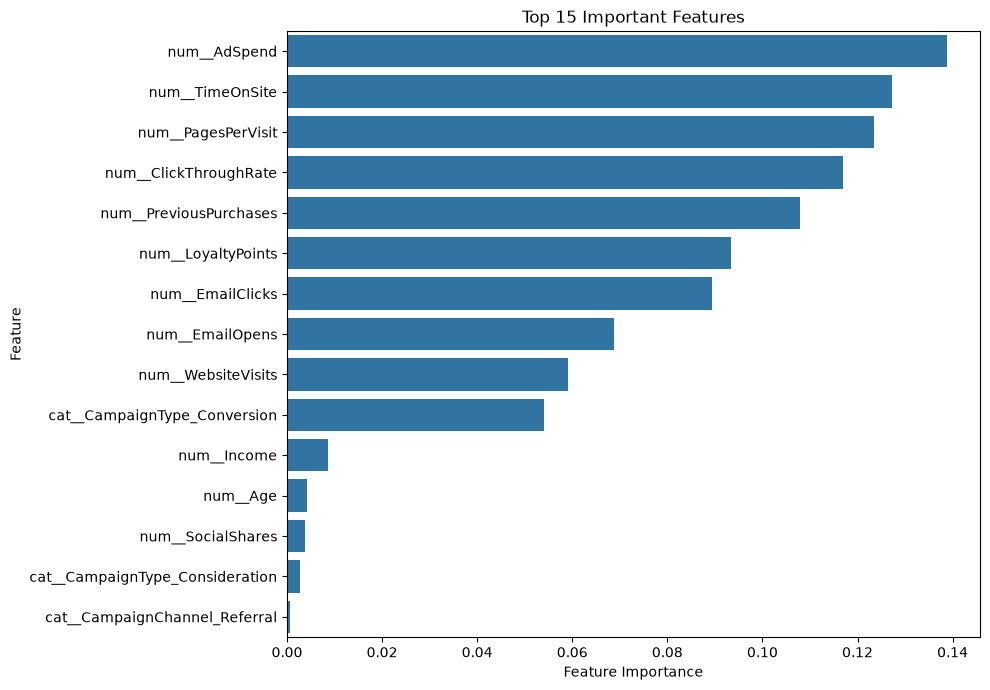

In [65]:
classifier = best_model.named_steps["classifier"]

feature_names = (
    best_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

if hasattr(classifier, "feature_importances_"):

    importance_values = classifier.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance_values
    })

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    )

    print(importance_df.head(15))

    plt.figure(figsize=(10, 7))

    sns.barplot(
        data=importance_df.head(15),
        x="Importance",
        y="Feature"
    )

    plt.title("Top 15 Important Features")
    plt.xlabel("Feature Importance")
    plt.ylabel("Feature")

    plt.tight_layout()
    plt.show()

elif hasattr(classifier, "coef_"):

    coefficient_df = pd.DataFrame({
        "Feature": feature_names,
        "Coefficient": classifier.coef_[0]
    })

    coefficient_df["Absolute Coefficient"] = (
        coefficient_df["Coefficient"].abs()
    )

    coefficient_df = coefficient_df.sort_values(
        by="Absolute Coefficient",
        ascending=False
    )

    print(coefficient_df.head(15))

    plt.figure(figsize=(10, 7))

    sns.barplot(
        data=coefficient_df.head(15),
        x="Absolute Coefficient",
        y="Feature"
    )

    plt.title("Top 15 Features by Absolute Coefficient")
    plt.xlabel("Absolute Coefficient")
    plt.ylabel("Feature")

    plt.tight_layout()
    plt.show()

else:
    print("This model does not provide native feature importance.")

In [66]:
joblib.dump(
    best_model,
    "customer_conversion_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [67]:
loaded_model = joblib.load(
    "customer_conversion_model.pkl"
)

print("Model loaded successfully!")

Model loaded successfully!


In [68]:
# Example customer using the first row of the test dataset
sample_customer = X_test.iloc[[0]].copy()

# Predict conversion
prediction = loaded_model.predict(sample_customer)[0]

# Estimate conversion probability
probability = loaded_model.predict_proba(
    sample_customer
)[0, 1]

print("Predicted Conversion:", prediction)

print(
    f"Conversion Probability: {probability:.2%}"
)

if prediction == 1:
    print("Prediction: Customer is likely to convert.")
else:
    print("Prediction: Customer is less likely to convert.")

Predicted Conversion: 1
Conversion Probability: 95.08%
Prediction: Customer is likely to convert.


In [1]:
import streamlit as st

ModuleNotFoundError: No module named 'streamlit'